# Program inversion

ProbJax can invert a JAX function by tracing it to a jaxpr and walking the
program backwards, replacing each primitive with its registered inverse. The
result is ordinary JAX code: it can be `jit`-ed, `vmap`-ed, and differentiated,
and no interpreter remains at runtime.

This notebook covers the common cases, the failure mode you should expect
(`nan`, not an exception), and how to attach an analytic inverse when
structural inversion is not enough.

In [1]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

from probjax.core import (
    custom_inverse,
    inverse,
    inverse_and_logabsdet,
)

## Inverting a tree of operations

A simple monotone function inverts elementwise. `inverse_and_logabsdet` also
returns the log-determinant of the **inverse** map, which is the term a change
of variables needs.

In [2]:
def forward(x):
    return 2.0 * jnp.exp(x) + 1.0


y = forward(jnp.array([0.4, 1.0]))
x = inverse(forward)(y)
print("y      :", y)
print("inverse:", x)
print("forward:", forward(x))

x, log_det = inverse_and_logabsdet(forward)(y)
print("log|det J_inv|:", log_det)

y      : [3.9836493 6.4365635]
inverse: [0.39999998 1.        ]
forward: [3.9836493 6.4365635]
log|det J_inv|: -2.7862945


The inverse is a normal JAX function. Jit and vmap it like any other:

In [3]:
jitted = jax.jit(inverse(forward))
batched = jax.vmap(inverse(forward))
print("jit   :", jitted(y))
print("vmap  :", batched(y[:, None])[:, 0])

jit   : [0.39999998 1.        ]
vmap  : [0.39999998 1.        ]


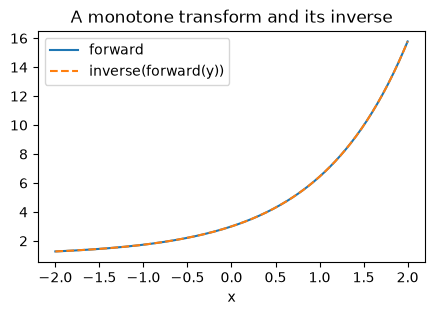

In [4]:
grid = jnp.linspace(-2.0, 2.0, 200)
values = forward(grid)
plt.figure(figsize=(5, 3))
plt.plot(grid, values, label="forward")
plt.plot(inverse(forward)(values), values, "--", label="inverse(forward(y))")
plt.xlabel("x")
plt.legend()
plt.title("A monotone transform and its inverse")
plt.show()

## Affine fan-out

A value used twice is the interesting case. If the program is affine in the
target, the inverse is a linear solve; this works pointwise (`3x - x`) and for
coupled components (`sum(x) - x`).

In [5]:
print("pointwise:", inverse(lambda t: 3.0 * t - t)(jnp.array([4.0, 6.0])))

recovered, log_det = inverse_and_logabsdet(
    lambda t: jnp.sum(t) * jnp.ones(2) - t
)(jnp.array([1.0, 2.0]))
print("coupled:  ", recovered)
print("log|det|: ", log_det)

pointwise: [2. 3.]


coupled:   [2. 1.]
log|det|:  0.0


## There is no solver: nonlinear fan-out returns `nan`

Inverting one equation at a time cannot undo a variable used twice
nonlinearly. The failure is silent by design; check `jnp.isfinite` on results
you have not inverted before.

In [6]:
nonlinear = inverse(lambda t: t + jnp.tanh(t))(jnp.asarray(1.0))
print("inverse(x + tanh(x)):", nonlinear)

inverse(x + tanh(x)): nan


## Shape changes need an `input_template`

When the output does not have the same structure as the input (`tile`,
padding, concatenation), pass an example input so the true program is staged.

In [7]:
x = jnp.array([1.0, 2.0])
tiled = inverse(lambda t: jnp.tile(t, 2), input_template=x)(jnp.tile(x, 2))
print("recovered:", tiled)

recovered: [1. 2.]


## Supplying an analytic inverse

`custom_inverse` attaches an inverse and its log-determinant to a function. The
interpreter then uses that rule instead of trying to derive one. This is how
the normalizing flows get exact, cheap inverses.

In [8]:
@custom_inverse
def affine(x, scale, shift):
    return x * scale + shift


@affine.definv_and_logdet
def _(y, scale, shift):
    return (y - shift) / scale, -jnp.log(jnp.abs(scale))


x, log_det = inverse_and_logabsdet(affine)(jnp.asarray(7.0), 2.0, 1.0)
print("x      :", x)
print("log|det|:", log_det)

x      : 3.0
log|det|: -0.6931472


`inv_argnum` chooses a non-leading argument and `static_argnums` marks
configuration arguments. Registered inverses are checked against the argument
they claim to invert, so a wrong shape or pytree fails loudly instead of
silently returning a number.

## Guards

Some inverses are only defined for some inputs. Those guards produce `nan`
exactly where no preimage exists; with `jax.experimental.checkify` and
`inverse_checks` they can become hard errors instead.

In [9]:
scale = jnp.asarray([0.0, 2.0])
recovered = inverse(lambda t: t * scale)(jnp.asarray([5.0, 4.0]))
print("recovered:", recovered)
print("element 0 has no preimage:", bool(jnp.isnan(recovered[0])))

recovered: [nan  2.]
element 0 has no preimage: True


## Takeaways

- `inverse(f)` returns ordinary JAX code; `inverse_and_logabsdet(f)` adds the
  change-of-variables term.
- Affine fan-out is solved, nonlinear fan-out returns `nan`. Check finite
  values when inverting something new.
- Use `input_template` for shape-changing programs and `custom_inverse` when
  you have a better analytic inverse.
- Guards return `nan` where the inverse does not exist; pair `inverse_checks`
  with `checkify` to turn them into errors.